# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer:


I predict that the most likely to survive profile will be a female child or young passenger traveling in first class, with family members aboard, and embarking from Cherbourg. I predict that the least likely to survive profile will be an adult male traveling in third class, without parents, children, siblings, or a spouse aboard, and embarking from Southampton. My predictions are based on my prior knowledge of the Titanic evacuation, particularly that women and children were given priority for lifeboats and that passenger class may have affected passengers' access to evacuation areas. I am less certain about the effects of traveling with family members or embarkation port, so I will use the data to determine whether those parts of my prediction are supported.

## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
titanic_df = pd.read_csv("data/titanic_passengers.csv")

In [3]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
titanic_df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer:


Each row represents one passenger in the Titanic dataset. The target feature is Survived, which records whether the passenger survived the disaster. A value of 0 means the passenger did not survive, while a value of 1 means the passenger survived.

Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature       | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| ------------- | ----------------------------------------------- | ----------------- | -------------: |
| `PassengerId` | Identifier                                      | int64             |              0 |
| `Name`        | Identifier                                      | str               |              0 |
| `Survived`    | Categorical                                     | int64             |              0 |
| `Pclass`      | Categorical                                     | int64             |              0 |
| `Sex`         | Categorical                                     | str               |              0 |
| `Age`         | Quantitative                                    | float64           |            177 |
| `Parch`       | Categorical                                     | int64             |              0 |
| `SibSp`       | Categorical                                     | int64             |              0 |
| `Embarked`    | Categorical                                     | str               |              2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer:


| Age-group label | Exact rule (including boundary values) | Reason for this choice                                                                                          |
| --------------- | -------------------------------------- | --------------------------------------------------------------------------------------------------------------- |
| Child           | Age < 18                               | Separates minors from adult passengers and allows comparison of children's survival.                            |
| Young Adult     | 18 ≤ Age < 30                          | Represents younger adult passengers as a distinct group.                                                        |
| Adult           | 30 ≤ Age < 50                          | Represents middle-aged adult passengers.                                                                        |
| Older Adult     | Age ≥ 50                               | Separates older passengers who may have experienced different survival outcomes.                                |
| Unknown         | Age is missing                         | Preserves the 177 passengers whose ages are unknown instead of incorrectly assigning them to another age group. |


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:
# Create age_group and display its category counts, including unknown ages.

titanic_df["age_group"] = "Unknown"

titanic_df.loc[titanic_df["Age"] < 18, "age_group"] = "Child"

titanic_df.loc[
    (titanic_df["Age"] >= 18) & (titanic_df["Age"] < 30),
    "age_group"
] = "Young Adult"

titanic_df.loc[
    (titanic_df["Age"] >= 30) & (titanic_df["Age"] < 50),
    "age_group"
] = "Adult"

titanic_df.loc[
    titanic_df["Age"] >= 50,
    "age_group"
] = "Older Adult"

titanic_df["age_group"].value_counts()

age_group
Young Adult    271
Adult          256
Unknown        177
Child          113
Older Adult     74
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:


None of the age groups are extremely small. The smallest known-age group is Older Adult with 74 passengers, followed by Child with 113. Young Adult has 271 passengers and Adult has 256. There are also 177 passengers with unknown ages. I will keep the original age groups because they provide meaningful age categories with reasonable group sizes, while preserving passengers with missing ages as Unknown rather than assigning them to another group.

### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [7]:
# Display Parch and SibSp category counts.

print("Parch counts:")
print(titanic_df["Parch"].value_counts().sort_index())

print("\nSibSp counts:")
print(titanic_df["SibSp"].value_counts().sort_index())

Parch counts:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

SibSp counts:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer:


For both Parch and SibSp, I will use three categories: None (0), One (1), and Two or More (2 or greater). I grouped the higher values because several individual categories contain very few passengers, which would make survival percentages unstable and difficult to compare. I will not exclude any passengers from the Parch or SibSp comparisons because these features have no missing values. For Embarked, I will exclude the 2 passengers with unknown embarkation ports from only that comparison rather than guessing their port. Each comparison will use all passengers with a known value for the feature being analyzed as its denominator. For the age-group comparison, passengers with missing ages will remain in the Unknown category.

In [8]:
# Create grouped travel-companion categories.

titanic_df["Parch_group"] = "Two or More"
titanic_df.loc[titanic_df["Parch"] == 0, "Parch_group"] = "None"
titanic_df.loc[titanic_df["Parch"] == 1, "Parch_group"] = "One"

titanic_df["SibSp_group"] = "Two or More"
titanic_df.loc[titanic_df["SibSp"] == 0, "SibSp_group"] = "None"
titanic_df.loc[titanic_df["SibSp"] == 1, "SibSp_group"] = "One"

print("Grouped Parch counts:")
print(titanic_df["Parch_group"].value_counts())

print("\nGrouped SibSp counts:")
print(titanic_df["SibSp_group"].value_counts())

Grouped Parch counts:
Parch_group
None           678
One            118
Two or More     95
Name: count, dtype: int64

Grouped SibSp counts:
SibSp_group
None           608
One            209
Two or More     74
Name: count, dtype: int64


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [9]:
# Create and display the count cross-tab.

age_crosstab = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"]
)

age_crosstab

Survived,0,1
age_group,,
Adult,149,107
Child,52,61
Older Adult,47,27
Unknown,125,52
Young Adult,176,95


In [10]:
# Calculate conditional percentages and display only the survived column.

age_survival_pct = (
    pd.crosstab(
        titanic_df["age_group"],
        titanic_df["Survived"],
        normalize="index"
    ) * 100
)

age_survival_pct[1].round(2)

age_group
Adult          41.80
Child          53.98
Older Adult    36.49
Unknown        29.38
Young Adult    35.06
Name: 1, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [11]:
# Display joint percentages.

age_joint_pct = (
    pd.crosstab(
        titanic_df["age_group"],
        titanic_df["Survived"],
        normalize="all"
    ) * 100
)

age_joint_pct.round(2)

Survived,0,1
age_group,,
Adult,16.72,12.01
Child,5.84,6.85
Older Adult,5.27,3.03
Unknown,14.03,5.84
Young Adult,19.75,10.66


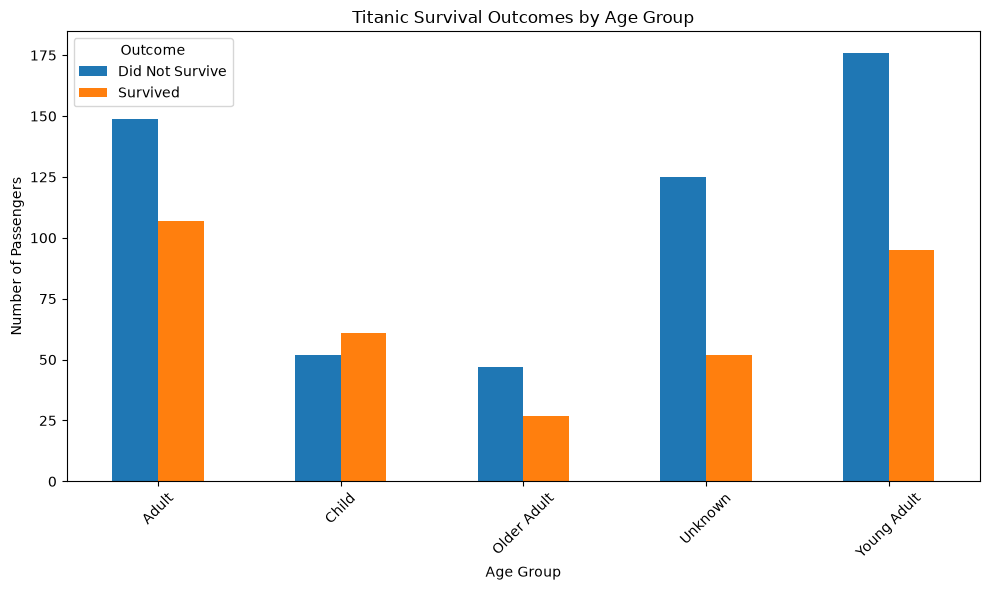

In [12]:
# Create a count chart showing both survival outcomes.

age_crosstab.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Titanic Survival Outcomes by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=45)
plt.legend(["Did Not Survive", "Survived"], title="Outcome")
plt.tight_layout()
plt.show()

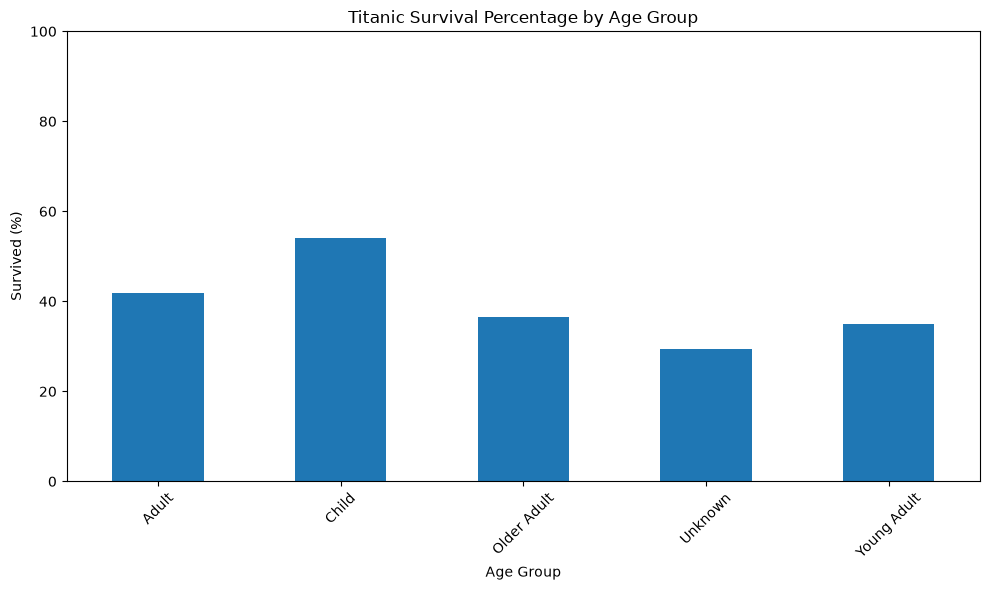

In [13]:
# Plot the conditional percentage who survived.

age_survival_pct[1].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Titanic Survival Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [14]:
# Create and display the count cross-tab.

sex_crosstab = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"]
)

sex_crosstab

Survived,0,1
Sex,,
female,81,233
male,468,109


In [15]:
# Calculate conditional percentages and display only the survived column.

sex_survival_pct = (
    pd.crosstab(
        titanic_df["Sex"],
        titanic_df["Survived"],
        normalize="index"
    ) * 100
)

sex_survival_pct[1].round(2)

Sex
female    74.20
male      18.89
Name: 1, dtype: float64

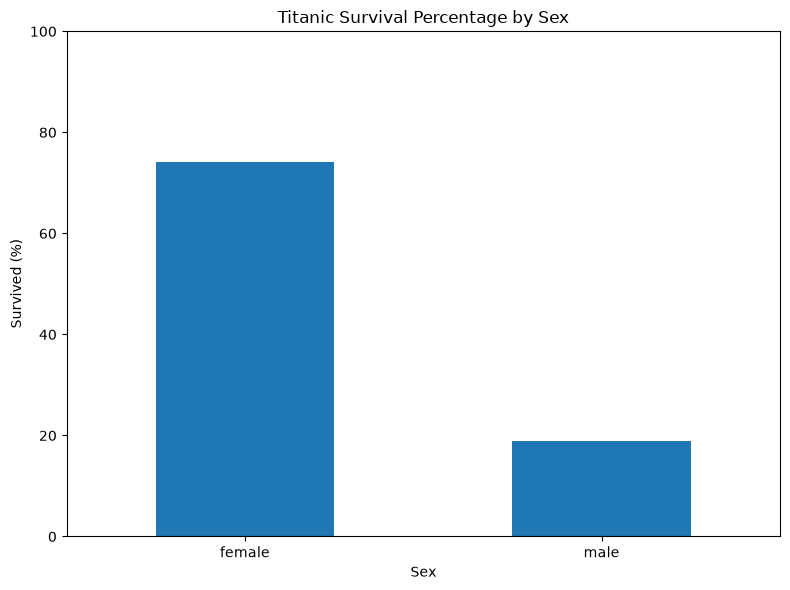

In [16]:
# Plot the conditional percentage who survived.

sex_survival_pct[1].plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Titanic Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [17]:
# Create and display the count cross-tab.

pclass_crosstab = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"]
)

pclass_crosstab

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [18]:
# Calculate conditional percentages and display only the survived column.

pclass_survival_pct = (
    pd.crosstab(
        titanic_df["Pclass"],
        titanic_df["Survived"],
        normalize="index"
    ) * 100
)

pclass_survival_pct[1].round(2)

Pclass
1    62.96
2    47.28
3    24.24
Name: 1, dtype: float64

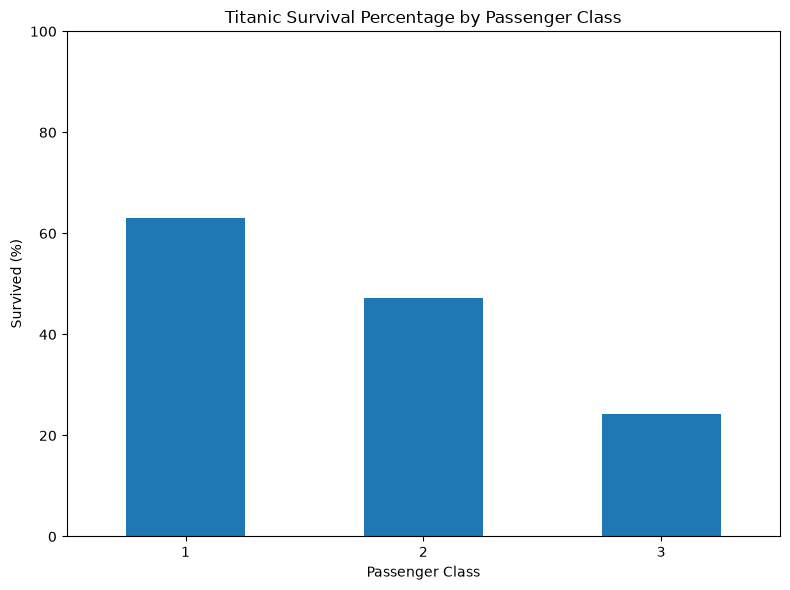

In [19]:
# Plot the conditional percentage who survived.

pclass_survival_pct[1].plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Titanic Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [20]:
# Create and display the count cross-tab.

parch_crosstab = pd.crosstab(
    titanic_df["Parch_group"],
    titanic_df["Survived"]
)

parch_crosstab

Survived,0,1
Parch_group,,
None,445,233
One,53,65
Two or More,51,44


In [21]:
# Calculate conditional percentages and display only the survived column.

parch_survival_pct = (
    pd.crosstab(
        titanic_df["Parch_group"],
        titanic_df["Survived"],
        normalize="index"
    ) * 100
)

parch_survival_pct[1].round(2)

Parch_group
None           34.37
One            55.08
Two or More    46.32
Name: 1, dtype: float64

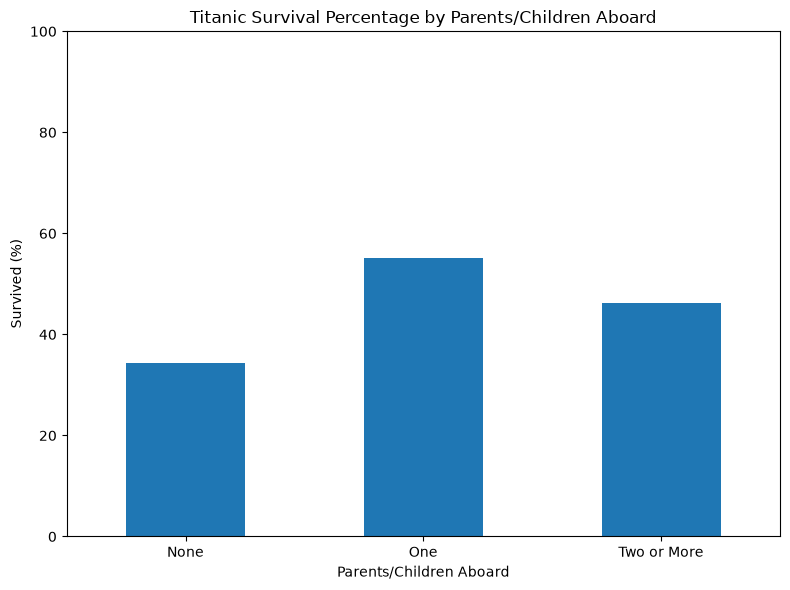

In [22]:
# Plot the conditional percentage who survived.

parch_survival_pct[1].plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Titanic Survival Percentage by Parents/Children Aboard")
plt.xlabel("Parents/Children Aboard")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [23]:
# Create and display the count cross-tab.

sibsp_crosstab = pd.crosstab(
    titanic_df["SibSp_group"],
    titanic_df["Survived"]
)

sibsp_crosstab

Survived,0,1
SibSp_group,,
None,398,210
One,97,112
Two or More,54,20


In [24]:
# Calculate conditional percentages and display only the survived column.

sibsp_survival_pct = (
    pd.crosstab(
        titanic_df["SibSp_group"],
        titanic_df["Survived"],
        normalize="index"
    ) * 100
)

sibsp_survival_pct[1].round(2)

SibSp_group
None           34.54
One            53.59
Two or More    27.03
Name: 1, dtype: float64

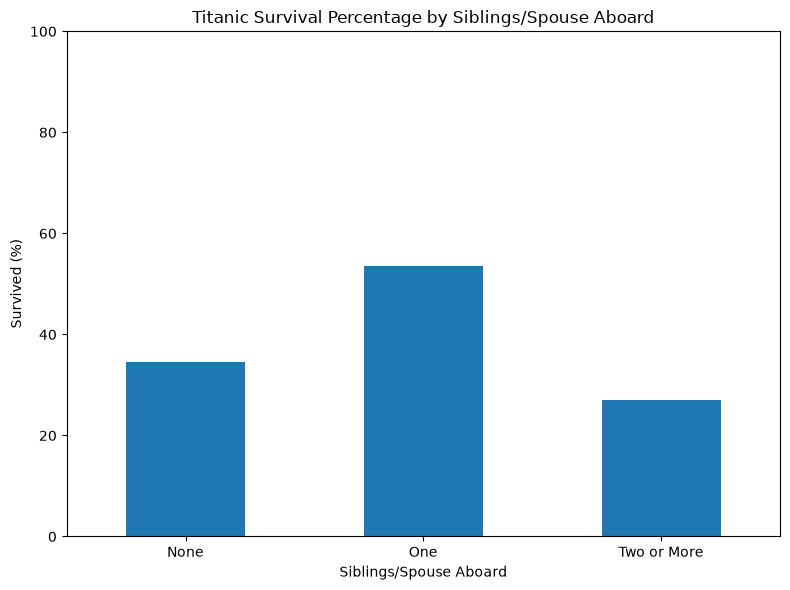

In [25]:
# Plot the conditional percentage who survived.

sibsp_survival_pct[1].plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Titanic Survival Percentage by Siblings/Spouse Aboard")
plt.xlabel("Siblings/Spouse Aboard")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [26]:
# Create and display the count cross-tab.

embarked_crosstab = pd.crosstab(
    titanic_df["Embarked"],
    titanic_df["Survived"]
)

embarked_crosstab

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [27]:
# Calculate conditional percentages and display only the survived column.

embarked_survival_pct = (
    pd.crosstab(
        titanic_df["Embarked"],
        titanic_df["Survived"],
        normalize="index"
    ) * 100
)

embarked_survival_pct[1].round(2)

Embarked
C    55.36
Q    38.96
S    33.70
Name: 1, dtype: float64

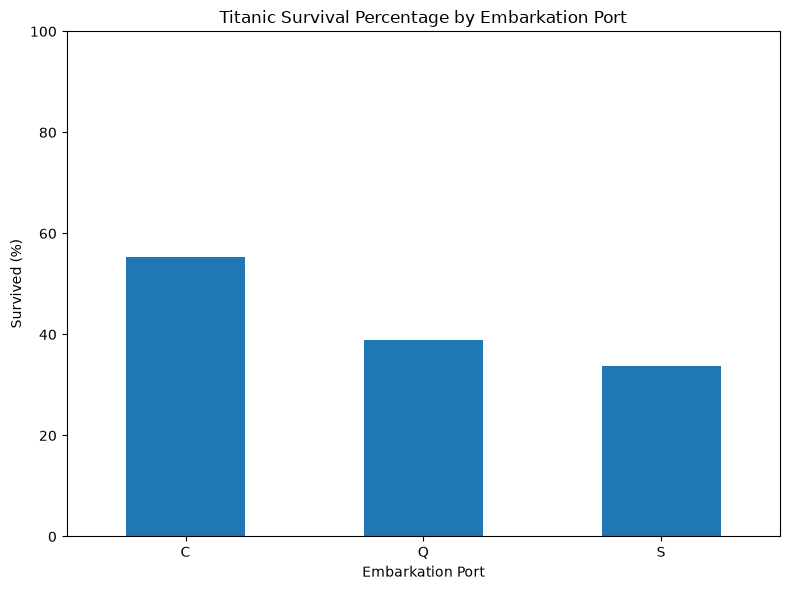

In [28]:
# Plot the conditional percentage who survived.

embarked_survival_pct[1].plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Titanic Survival Percentage by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature                        | Highest-survival category, percentage, and group size     | Lowest-survival category, percentage, and group size         |
| ------------------------------ | --------------------------------------------------------- | ------------------------------------------------------------ |
| Sex (example)                  | Female: 74.2% survived (233 of 314 passengers).           | Male: 18.9% survived (109 of 577 passengers).                |
| **Age groups**                 | **Child: 54.0% survived (61 of 113 passengers).**         | **Unknown: 29.4% survived (52 of 177 passengers).**          |
| **Passenger class**            | **1st class: 63.0% survived (136 of 216 passengers).**    | **3rd class: 24.2% survived (119 of 491 passengers).**       |
| **Parents or children aboard** | **One: 55.1% survived (65 of 118 passengers).**           | **None: 34.4% survived (233 of 678 passengers).**            |
| **Siblings or spouse aboard**  | **One: 53.6% survived (112 of 209 passengers).**          | **Two or More: 27.0% survived (20 of 74 passengers).**       |
| **Embarkation port**           | **Cherbourg (C): 55.4% survived (93 of 168 passengers).** | **Southampton (S): 33.7% survived (217 of 644 passengers).** |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer:


A joint percentage uses all 891 passengers as the denominator. For example, children who survived represent 6.85% of the entire dataset (61 of 891 passengers). A conditional percentage instead uses only the passengers within that age group as the denominator. Of the 113 children, 61 survived, giving children a survival percentage of about 54.0%. The conditional percentage is more useful for answering the survival-likelihood question because it compares the probability of survival within each age group rather than the group's share of the entire dataset.

## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [29]:
# Check age-group boundaries and unknown ages.

age_boundary_check = titanic_df.groupby("age_group", dropna=False)["Age"].agg(
    ["count", "min", "max"]
)

age_boundary_check

,count,min,max
age_group,,,
Adult,256,30.00,49.0
Child,113,0.42,17.0
Older Adult,74,50.00,80.0
Unknown,0,NaN,NaN
Young Adult,271,18.00,29.0


In [30]:
# Check travel-companion category mappings if you created grouped features.

print("Parch mapping:")
display(pd.crosstab(titanic_df["Parch"], titanic_df["Parch_group"]))

print("\nSibSp mapping:")
display(pd.crosstab(titanic_df["SibSp"], titanic_df["SibSp_group"]))

Parch mapping:


Parch_group,None,One,Two or More
Parch,,,
0,678,0,0
1,0,118,0
2,0,0,80
3,0,0,5
4,0,0,4
5,0,0,5
6,0,0,1



SibSp mapping:


SibSp_group,None,One,Two or More
SibSp,,,
0,608,0,0
1,0,209,0
2,0,0,28
3,0,0,16
4,0,0,18
5,0,0,5
8,0,0,7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer:


The checks show that my age boundaries and category mappings match my intentions. Children have known ages from 0.42 through 17, Young Adults from 18 through 29, Adults from 30 through 49, and Older Adults from 50 through 80, so the groups do not overlap and the cutoff values were assigned correctly. The Unknown group contains the 177 passengers with missing ages, although the age-boundary count displays 0 because their Age values are missing. The Parch and SibSp checks also confirm that 0 maps to None, 1 maps to One, and all values of 2 or more map to Two or More. The survival percentages use all passengers within each relevant category as the denominator, not only survivors. I would be suspicious if ages appeared outside their intended boundaries, companion counts mapped to the wrong groups, or percentages did not agree with the count tables, but I did not find those problems. Some categories are smaller than others, especially the Older Adult age group (74 passengers), the SibSp Two or More group (74 passengers), and Queenstown embarkation group (77 passengers), so comparisons involving these groups should be interpreted with more caution.

## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element                | Most likely profile: category and evidence                                                             | Least likely profile: category and evidence                                                                      |
| ------------------------------ | ------------------------------------------------------------------------------------------------------ | ---------------------------------------------------------------------------------------------------------------- |
| **Sex**                        | Female: **74.2% survived (233 of 314 passengers).**                                                    | Male: **18.9% survived (109 of 577 passengers).**                                                                |
| **Age groups**                 | Child: **54.0% survived (61 of 113 passengers).**                                                      | Young Adult: **35.1% survived (95 of 271 passengers).** *Revised from Unknown to obtain a real passenger match.* |
| **Passenger class**            | 1st class: **63.0% survived (136 of 216 passengers).**                                                 | 3rd class: **24.2% survived (119 of 491 passengers).**                                                           |
| **Parents or children aboard** | None: **34.4% survived (233 of 678 passengers).** *Revised from One to obtain a real passenger match.* | None: **34.4% survived (233 of 678 passengers).**                                                                |
| **Siblings or spouse aboard**  | One: **53.6% survived (112 of 209 passengers).**                                                       | Two or More: **27.0% survived (20 of 74 passengers).**                                                           |
| **Embarkation port**           | Cherbourg (C): **55.4% survived (93 of 168 passengers).**                                              | Southampton (S): **33.7% survived (217 of 644 passengers).**                                                     |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer:


Based on the individual categorical comparisons and the revised profile needed to obtain a real passenger match, the most-likely-to-survive profile is a female child traveling in first class, with no parents or children aboard and one sibling or spouse aboard, who embarked at Cherbourg. The parents/children category was revised from One to None because the original six-characteristic combination did not match any real passenger in the dataset.

The least-likely-to-survive profile is a male Young Adult traveling in third class, with no parents or children aboard and two or more siblings or a spouse aboard, who embarked at Southampton. The age category was revised from Unknown to Young Adult because the original combination did not match a real passenger, and Young Adult had the lowest survival percentage among the known-age groups.

These revisions represent tradeoffs between selecting the highest- or lowest-survival category for every individual feature and creating a profile that actually exists in the dataset. The Unknown age category also does not represent a meaningful age characteristic, making Young Adult a more interpretable choice. Some categories have smaller group sizes, such as the SibSp Two or More group with 74 passengers, so those results should be interpreted cautiously. Finally, the percentages describe each characteristic separately and should not be multiplied together or treated as the survival probability for a passenger with the complete profile.

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [35]:
# Revised most-likely profile:
# Parch_group changed from "One" to "None" to obtain a real passenger.

most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female") &
    (titanic_df["age_group"] == "Child") &
    (titanic_df["Pclass"] == 1) &
    (titanic_df["Parch_group"] == "None") &
    (titanic_df["SibSp_group"] == "One") &
    (titanic_df["Embarked"] == "C")
]

most_likely_df[
    ["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass",
     "Parch", "Parch_group", "SibSp", "SibSp_group",
     "Embarked", "Survived"]
]

,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,Parch_group,SibSp,SibSp_group,Embarked,Survived
307,308,"Penasco y Castellana, Mrs. Victor de Satode (M...",female,17.0,Child,1,0,None,1,One,C,1


In [36]:
# Revised least-likely profile:
# age_group changed from "Unknown" to "Young Adult" to obtain a real passenger.

least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male") &
    (titanic_df["age_group"] == "Young Adult") &
    (titanic_df["Pclass"] == 3) &
    (titanic_df["Parch_group"] == "None") &
    (titanic_df["SibSp_group"] == "Two or More") &
    (titanic_df["Embarked"] == "S")
]

least_likely_df[
    ["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass",
     "Parch", "Parch_group", "SibSp", "SibSp_group",
     "Embarked", "Survived"]
]

,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,Parch_group,SibSp,SibSp_group,Embarked,Survived
69,70,"Kink, Mr. Vincenz",male,26.0,Young Adult,3,0,None,2,Two or More,S,0
392,393,"Gustafsson, Mr. Johan Birger",male,28.0,Young Adult,3,0,None,2,Two or More,S,0
565,566,"Davies, Mr. Alfred J",male,24.0,Young Adult,3,0,None,2,Two or More,S,0


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer:


My original Boolean filters used all six profile characteristics and did not use Survived as a filtering condition, but both original combinations returned no matching passengers. I therefore revised one characteristic in each profile while keeping all six elements. For the most-likely profile, I changed the parents/children category from One to None while retaining female, Child, first class, one sibling/spouse aboard, and embarkation at C. This revised profile produced one real passenger, PassengerId 308. For the least-likely profile, I changed the age category from Unknown to Young Adult while retaining male, third class, no parents/children aboard, two or more siblings/spouse aboard, and embarkation at S. Young Adult was the lowest-survival category among the known-age groups. This revised profile produced three real passengers, PassengerIds 70, 393, and 566. These revisions preserve all six profile elements while producing real matches from the dataset.

### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:


I selected Peñasco y Castellana, Mrs. Victor de Satode (Maria Josefa Perez de Soto y Vallejo), PassengerId 308, from my most-likely-to-survive list. I matched her to the Encyclopedia Titanica biography using her name, first-class passenger status, and embarkation at Cherbourg.

An interesting fact is that she traveled aboard the Titanic with her husband and personal maid. During the sinking, she and her maid escaped together in lifeboat 8. Her husband did not survive.

The biography contains an age discrepancy. My dataset records her as 17 years old, and the biography's introductory paragraph also says 17. However, its passenger summary lists her as 22 years old. I kept the dataset's recorded age for my analysis and noted the disagreement.

Biography URL:
https://www.encyclopedia-titanica.org/titanic-survivor/maria-penasco.html

**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:


I selected Kink, Mr. Vincenz, PassengerId 70, from my least-likely-to-survive list. I matched him to the Encyclopedia Titanica biography using his name, age of 26, third-class passenger status, and embarkation at Southampton.

An interesting fact is that Vincenz was traveling with his siblings and other relatives because they planned to immigrate to Milwaukee, Wisconsin. After the Titanic struck the iceberg, he and his brother Anton went to investigate. During the evacuation, Vincenz became separated from his family and did not survive.

The biographical information agrees with the identifying details in my dataset.

Biography URL:
https://www.encyclopedia-titanica.org/titanic-victim/vincenz-kink.html

After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [37]:
# Select one passenger from each profile
selected_most = most_likely_df.loc[
    most_likely_df["PassengerId"] == 308
]

selected_least = least_likely_df.loc[
    least_likely_df["PassengerId"] == 70
]

# Combine the selected passengers
selected_passengers = pd.concat([
    selected_most,
    selected_least
])

# Display names, IDs, and actual survival outcomes
selected_passengers[
    ["PassengerId", "Name", "Survived"]
]

,PassengerId,Name,Survived
307,308,"Penasco y Castellana, Mrs. Victor de Satode (M...",1
69,70,"Kink, Mr. Vincenz",0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer:


Both passengers' actual survival outcomes aligned with their profile labels. Maria Josefa Peñasco y Castellana was classified as most likely to survive, and she survived the sinking. Vincenz Kink was classified as least likely to survive, and he did not survive.

These results support the general patterns observed in the dataset, but they do not mean that every passenger with similar characteristics experienced the same outcome. Group survival percentages describe overall trends rather than guaranteeing an individual's survival.

The biographies agree with the survival outcomes recorded in the dataset. However, Maria Josefa's biography contains conflicting age information, listing her as 17 in one section and 22 in another. My dataset records her age as 17, so I retained that value while documenting the discrepancy.

### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer:


I recommend using Maria Josefa Peñasco y Castellana (PassengerId 308) for the most-likely-to-survive character and Vincenz Kink (PassengerId 70) for the least-likely-to-survive character. Maria's profile includes several categories associated with higher survival: females had a 74.2% survival rate (233 of 314), children had a 54.0% survival rate (61 of 113), first-class passengers had a 63.0% survival rate (136 of 216), passengers with one sibling or spouse aboard had a 53.6% survival rate (112 of 209), and passengers embarking at Cherbourg had a 55.4% survival rate (93 of 168). Her biography also provides historical details that can help develop the character beyond the numerical data.

Vincenz's profile contains several categories associated with lower survival: males had an 18.9% survival rate (109 of 577), Young Adults had a 35.1% survival rate (95 of 271), third-class passengers had a 24.2% survival rate (119 of 491), passengers with no parents or children aboard had a 34.4% survival rate (233 of 678), passengers with two or more siblings or a spouse aboard had a 27.0% survival rate (20 of 74), and passengers embarking at Southampton had a 33.7% survival rate (217 of 644). His biography also gives the director additional information about his family and planned immigration to Milwaukee.

The completed profiles are similar to my initial predictions, but two revisions were necessary because the original combinations did not match real passengers. For the most-likely profile, I changed the parents/children category from One to None. For the least-likely profile, I changed the age category from Unknown to Young Adult, which was also more meaningful because Unknown represents missing data rather than an actual age group. These tradeoffs allowed both profiles to represent real Titanic passengers while remaining grounded in the numerical evidence.

## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer:


The director should not interpret these profiles as individual survival probabilities or assume that any characteristic caused a passenger to survive or die. Each percentage was calculated by comparing one feature with survival separately. The characteristics may be related to one another, so the percentages cannot simply be multiplied together to predict an individual's outcome.

There are also limitations in the data. Some groups are relatively small, such as the SibSp Two or More group with only 74 passengers, which makes its percentage less reliable for broad conclusions. Some passengers have missing ages, and the Unknown age category represents missing information rather than a meaningful age group. The categories themselves, such as the age ranges and grouped family counts, are choices made for this analysis and different definitions could produce different comparisons. Historical records can also contain uncertainty or conflicting information, as seen in the differing age information for Maria Josefa Peñasco y Castellana. Therefore, the results should be presented as patterns in this dataset rather than proof of causation or guaranteed outcomes for individual passengers.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:


Yes. I used AI to help revise my passenger profiles when the original combinations did not match any passengers in the dataset. I checked the suggested revisions against my dataset and accepted them.

## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
